# **Fase 2: Entrenamiento y Validación del Modelo Supervisado**
## **Comparación de DummyClassifier, Árbol de Decisión y Random Forest**

En este notebook cargamos `dataset_tres_en_raya.csv`, dividimos los datos en entrenamiento (80 %) y prueba (20 %) de forma estratificada, aplicamos **validación cruzada estratificada 5-fold** y comparamos tres algoritmos supervisados para seleccionar el modelo óptimo.

In [1]:
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

SEMILLA = 42
RUTA_CSV = Path("../data/dataset_tres_en_raya.csv")
RUTA_MODELO = Path("../models/modelo_rf_tres_en_raya.joblib")

datos = pd.read_csv(RUTA_CSV)
X = datos[[f"celda_{i}" for i in range(9)]]
y = datos["jugada_optima"]

X_ent, X_pru, y_ent, y_pru = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)
print(f"Total registros: {len(datos)} | Entrenamiento (80%): {len(X_ent)} | Prueba (20%): {len(X_pru)}")

Total registros: 2423 | Entrenamiento (80%): 1938 | Prueba (20%): 485


## **2. Validación cruzada estratificada (5-Fold) y comparación de modelos**

Evaluamos cada modelo bajo exactamente las mismas particiones estratificadas (`StratifiedKFold`, `k=5`, `random_state=42`) midiendo Exactitud (Accuracy), Desviación Estándar, F1-Score Macro y Latencia de Inferencia.

In [2]:
modelos = {
    "DummyClassifier (Modelo Base)": DummyClassifier(strategy="most_frequent"),
    "DecisionTreeClassifier (Prof. 10)": DecisionTreeClassifier(max_depth=10, random_state=SEMILLA),
    "RandomForestClassifier (150 árboles)": RandomForestClassifier(n_estimators=150, max_depth=15, random_state=SEMILLA),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas_resultados = []

for nombre, clf in modelos.items():
    scores = cross_validate(
        clf, X_ent, y_ent, cv=cv,
        scoring={"acc": "accuracy", "f1": "f1_macro"}
    )
    clf.fit(X_ent, y_ent)

    muestras = X_pru.iloc[:100]
    t0 = time.perf_counter()
    for i in range(len(muestras)):
        clf.predict(muestras.iloc[[i]])
    latencia_ms = ((time.perf_counter() - t0) / len(muestras)) * 1000

    pred_pru = clf.predict(X_pru)
    filas_resultados.append({
        "Modelo": nombre,
        "Accuracy CV (5-fold) %": round(scores["test_acc"].mean() * 100, 2),
        "Desv. Estándar %": round(scores["test_acc"].std() * 100, 2),
        "F1-Score Macro CV": round(scores["test_f1"].mean(), 3),
        "Accuracy Prueba (20%) %": round(accuracy_score(y_pru, pred_pru) * 100, 2),
        "Latencia (ms)": round(latencia_ms, 3),
    })

tabla_metricas = pd.DataFrame(filas_resultados)
display(tabla_metricas)

,Modelo,Accuracy CV (5-fold) %,Desv. Estándar %,F1-Score Macro CV,Accuracy Prueba (20%) %,Latencia (ms)
0,DummyClassifier (Modelo Base),18.89,0.10,0.035,18.97,0.115
1,DecisionTreeClassifier (Prof. 10),64.71,1.58,0.606,63.92,0.487
2,RandomForestClassifier (150 árboles),79.21,1.25,0.772,81.24,6.621


## **3. Exportación del modelo seleccionado y matriz de confusión**

Guardamos el modelo `RandomForestClassifier` entrenado en `models/modelo_rf_tres_en_raya.joblib` y visualizamos tanto la comparación de exactitud como la matriz de confusión en el conjunto de prueba.

Modelo Random Forest guardado en: ..\models\modelo_rf_tres_en_raya.joblib


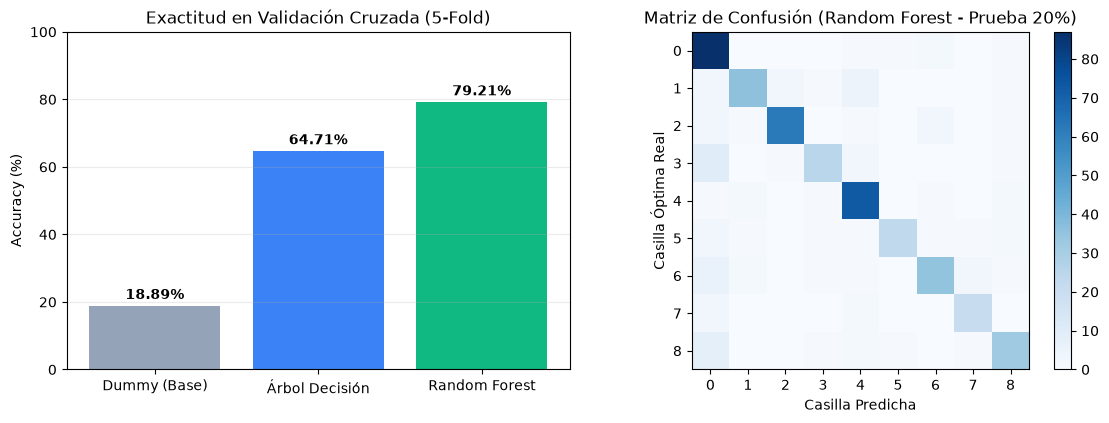

In [3]:
rf_final = RandomForestClassifier(n_estimators=150, max_depth=15, random_state=SEMILLA)
rf_final.fit(X_ent, y_ent)
joblib.dump(rf_final, RUTA_MODELO)
print("Modelo Random Forest guardado en:", RUTA_MODELO)

pred_rf = rf_final.predict(X_pru)
cm = confusion_matrix(y_pru, pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
colores = ["#94A3B8", "#3B82F6", "#10B981"]
bars = axes[0].bar(["Dummy (Base)", "Árbol Decisión", "Random Forest"], tabla_metricas["Accuracy CV (5-fold) %"], color=colores)
axes[0].set(title="Exactitud en Validación Cruzada (5-Fold)", ylabel="Accuracy (%)", ylim=(0, 100))
axes[0].grid(axis="y", alpha=0.25)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.2f}%", ha="center", fontweight="bold")

im = axes[1].imshow(cm, cmap="Blues")
axes[1].set(title="Matriz de Confusión (Random Forest - Prueba 20%)", xlabel="Casilla Predicha", ylabel="Casilla Óptima Real")
axes[1].set_xticks(range(9))
axes[1].set_yticks(range(9))
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
fig.savefig("../evidencias/fig1_comparacion_modelos.png", bbox_inches="tight", dpi=150)
plt.show()